# Proyecto 2 - Segunda parte: Regresión lineal múltiple
**Alumnos:** Cristian Martini, Franco Perrone

**Dataset:** Bike Sharing - alquileres diarios de bicicletas en Washington D.C. (2011 y 2012).

## 1. Carga de Datos y visualización de variables

In [ ]:
# imports
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

In [ ]:
# carga del dataset y detalles del mismo
df = pd.read_csv("day.csv")
print(df.shape)
df.head().round(2)

(731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


In [ ]:
# Detalle de tipo de datos y nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [ ]:
# Detalle estadistico de las columnas a utilizar
df[["temp", "atemp", "windspeed", "hum", "cnt"]].describe().round(2)

,temp,atemp,windspeed,hum,cnt
count,731.00,731.00,731.00,731.00,731.00
mean,0.50,0.47,0.19,0.63,4504.35
std,0.18,0.16,0.08,0.14,1937.21
min,0.06,0.08,0.02,0.00,22.00
25%,0.34,0.34,0.13,0.52,3152.00
50%,0.50,0.49,0.18,0.63,4548.00
75%,0.66,0.61,0.23,0.73,5956.00
max,0.86,0.84,0.51,0.97,8714.00


Se observa que las variables climáticas ya están normalizadas en el dataset original (valores entre 0 y 1). También se ve que la humedad mínima es 0, por lo que es probable que en lugar de dejar el dato nulo se haya completado con cero.

In [ ]:
# Chequeo y limpieza de ceros por nulos
mascara = df['hum'] > 0
df = df[mascara]
print(df.shape)

df[["temp", "atemp", "windspeed", "hum", "cnt"]].describe().round(2)

(730, 16)


,temp,atemp,windspeed,hum,cnt
count,730.00,730.00,730.00,730.00,730.00
mean,0.50,0.47,0.19,0.63,4509.67
std,0.18,0.16,0.08,0.14,1933.19
min,0.06,0.08,0.02,0.19,22.00
25%,0.34,0.34,0.13,0.52,3169.75
50%,0.50,0.49,0.18,0.63,4548.50
75%,0.66,0.61,0.23,0.73,5966.00
max,0.86,0.84,0.51,0.97,8714.00


Eliminamos una sola fila con humedad 0, porque ese valor no es posible en la realidad.

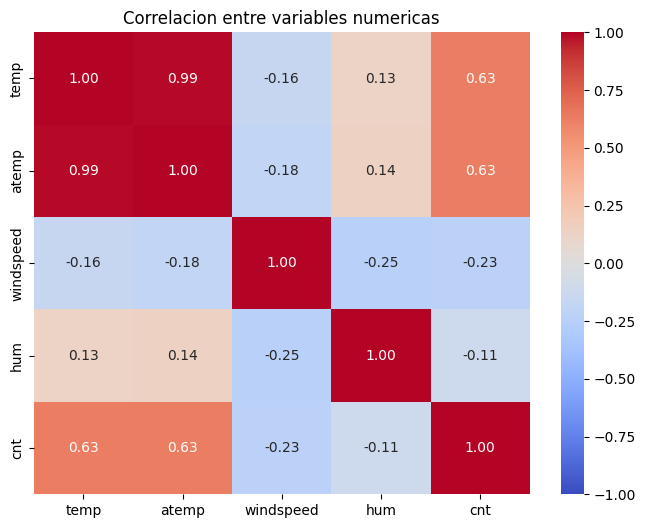

In [ ]:
# Heatmap para ver la correlacion entre variables

columnas = ["temp", "atemp", "windspeed", "hum", "cnt"]
correlaciones = df[columnas].corr()

plt.figure(figsize=(8,6))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlacion entre variables numericas")
plt.show()



En este caso podemos ver que "temp" (temperatura) y "atemp" (sensacion termica) tienen una correlacion muy alta entre si siendo dos Feature y afecta de manera negativa el modelo. Por otro lado, ambas son las que mayor correlación tienen con "cnt". Descartamos "atemp" y nos quedamos con "temp".

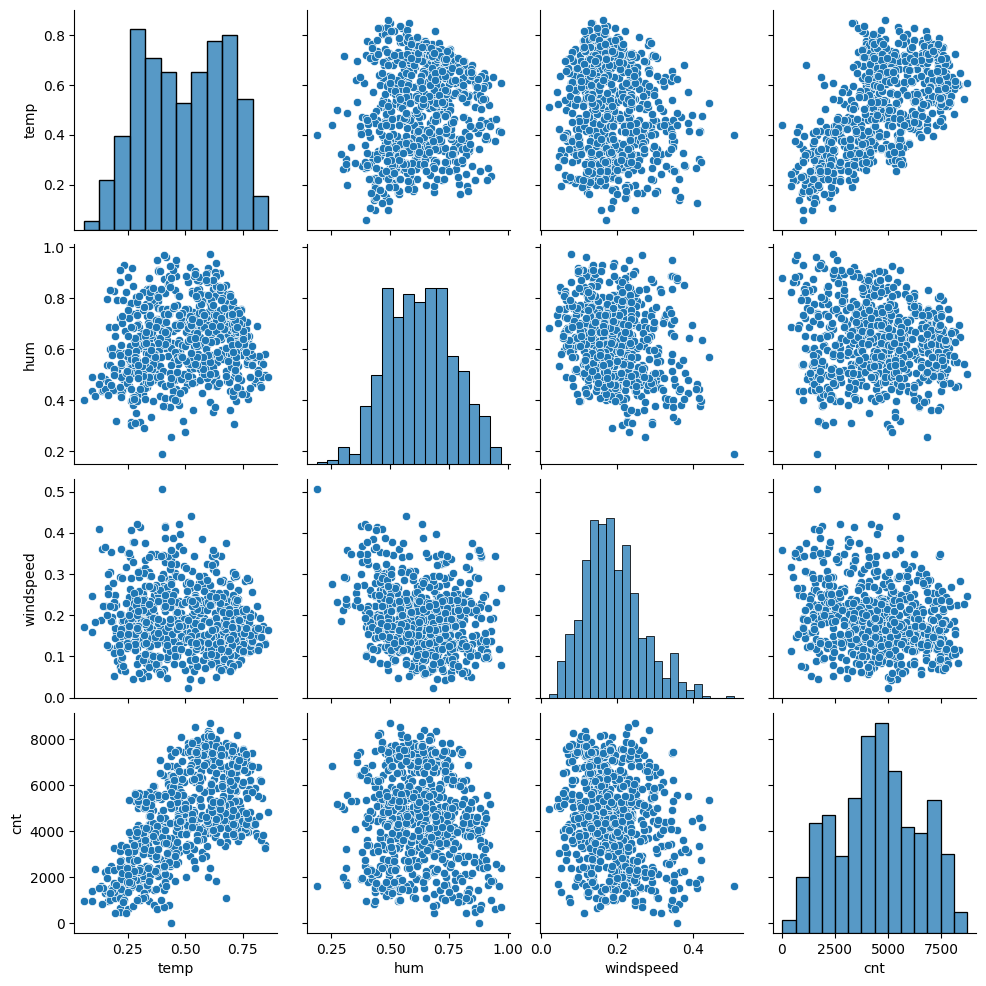

In [ ]:
# Pairplot para visualizar la forma que generan los dias respecto a la relacion entre las variables.

sns.pairplot(df[["temp", "hum", "windspeed", "cnt"]])
plt.show()

En estos graficos buscamos formas lineales con orientacion diagonal (linea que sube). La más marcada vemos que es la ya mencionada por su correlacion "cnt" con "temp". Se puede ver que en la parte final se ensancha en los dias con mayor registro de temperatura pero con mucha amplitud de alquileres.

In [ ]:
# Promedio de alquiler diario por año
df_yr = df.groupby("yr")["cnt"].mean()
print(df_yr.round())

yr
0    3413.0
1    5600.0
Name: cnt, dtype: float64


El promedio por año de alquileres pasa de 3413 en 2011 a 5600 en 2012 lo que puede explicar el ensanchamiento mencionado anteriormente

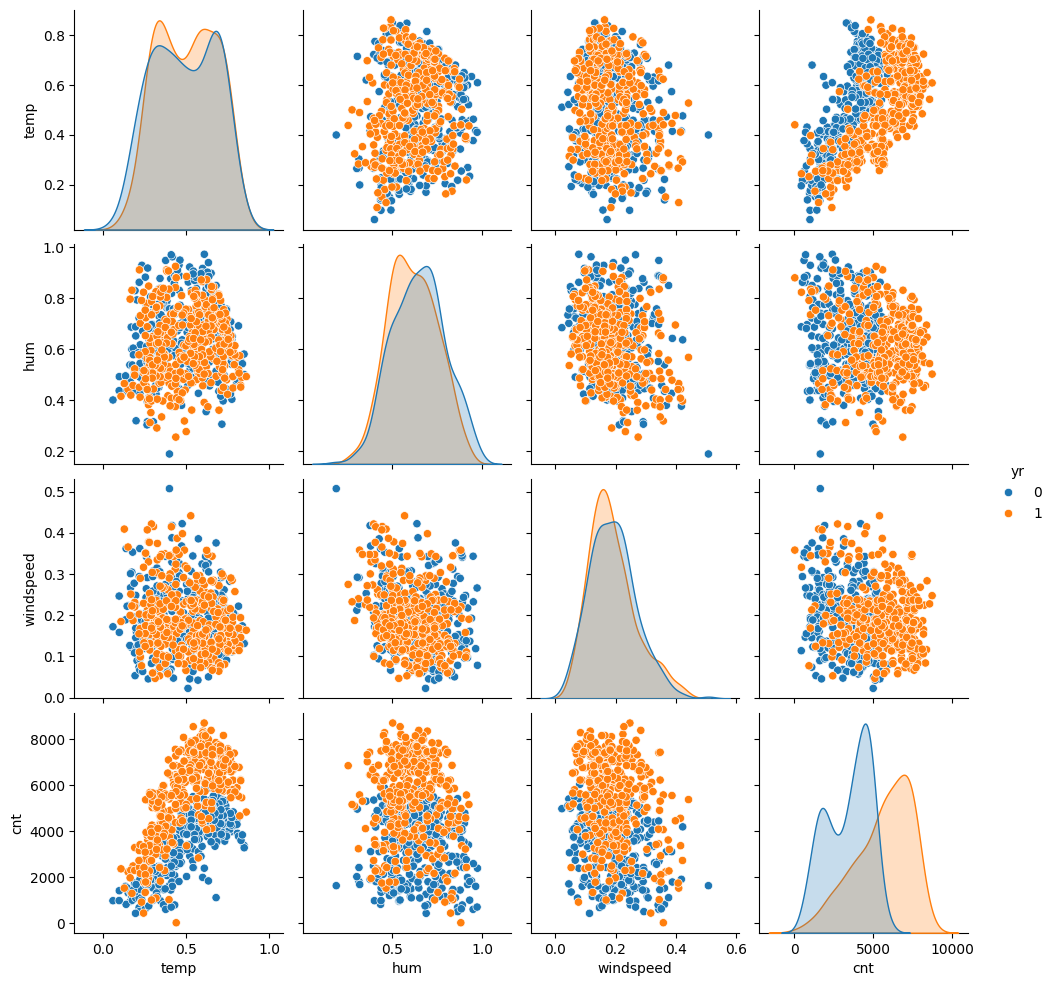

In [ ]:
sns.pairplot(df[["temp", "hum", "windspeed", "cnt", "yr"]], hue="yr")
plt.show()

Observando el gráfico "temp" sobre X y "cnt" sobre Y vemos que el año 2012 (color naranja) está por encima del 2011 (color azul). En ambos años "cnt" sube a medida que sube "temp". En el histograma el gráfico naranja quedó desplazado hacia la derecha lo cual coincide con el promedio de 5600 alquileres por dia que vimos en el groupby. Por esto, vamos a probar agregar "yr" como variable para comparar modelos.

##2. Cambio de estructura de datos a matricial


In [ ]:
# matriz de features
X = df[["temp", "hum", "windspeed"]].values

# vector con lo que queremos predecir
y = df["cnt"].values

print("X:", X.shape)
print("Y:", y.shape)

X: (730, 3)
Y: (730,)


In [ ]:
#modelo 2
X2 = df[["temp","hum", "windspeed", "yr"]].values

#usamos y del modelo 1

print("X2:", X2.shape)


X2: (730, 4)


##3. Particionado de datos en Entrenamiento y Test


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)



(584, 3)
(146, 3)


In [ ]:
#modelo 2
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

print(X2_train.shape)
print(X2_test.shape)

(584, 4)
(146, 4)


## 4. Generación del modelo con los datos de Entrenamiento


In [ ]:
#modelo 1
reg = LinearRegression()
reg.fit(X_train, y_train)

print("intercepto:", reg.intercept_.round(2))
print("coeficiente:", reg.coef_.round(2))

intercepto: 4154.7
coeficiente: [ 6694.25 -3179.23 -5014.04]


In [ ]:
#modelo 2
reg2 = LinearRegression()
reg2.fit(X2_train, y2_train)

print("intercepto:", reg2.intercept_.round(2))
print("coeficiente:", reg2.coef_.round(2))


intercepto: 2687.24
coeficiente: [ 6423.02 -2377.06 -4466.23  1932.11]


## 5. Evaluación del modelo con los datos de Entrenamiento


In [ ]:

#R2
r2_train = reg.score(X_train,y_train)

#prediccion
pred_train = reg.predict(X_train)

#MAE
mae_train = mean_absolute_error(y_train, pred_train)


print("R2 train:", round(r2_train, 3))
print("MAE train:", round(mae_train,1))


R2 train: 0.473
MAE train: 1155.1


In [ ]:
#modelo 2
r2_train2 = reg2.score(X2_train, y2_train)

pred_train2 = reg2.predict(X2_train)

mae_train2 = mean_absolute_error(y2_train, pred_train2)

print("R2 train 2:", round(r2_train2, 3))
print("MAE train 2:", round(mae_train2, 1))


R2 train 2: 0.717
MAE train 2: 812.9


##6. Evaluación del modelo con los datos de Test


In [ ]:

#R2
r2_test = reg.score(X_test,y_test)

#prediccion
pred_test = reg.predict(X_test)

#MAE
mae_test = mean_absolute_error(y_test, pred_test)


print("R2 test:", round(r2_test, 3))
print("MAE test:", round(mae_test,1))


R2 test: 0.429
MAE test: 1173.9


In [ ]:
#baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

r2_base = baseline.score(X_test,y_test)

pred_base = baseline.predict(X_test)

mae_base = mean_absolute_error(y_test, pred_base)

print("R2 baseline:", round(r2_base, 3))
print("MAE baseline:", round(mae_base, 1))

R2 baseline: -0.019
MAE baseline: 1591.8


Comparando el desempeño del modelo con el baseline, el modelo es claramente superior, pero tiene un desempeño limitado. Un R2 de 0.43 siendo 0.50 el minimo esperado.

In [ ]:
#Modelo 2

r2_test2 = reg2.score(X2_test, y2_test)

pred_test2 = reg2.predict(X2_test)

mae_test2 = mean_absolute_error(y2_test, pred_test2)

print("R2 test 2:", round(r2_test2, 3))
print("MAE test 2:", round(mae_test2, 1))


R2 test 2: 0.763
MAE test 2: 728.3


##Graficos de la regresion lineal multiple

Modelo 1

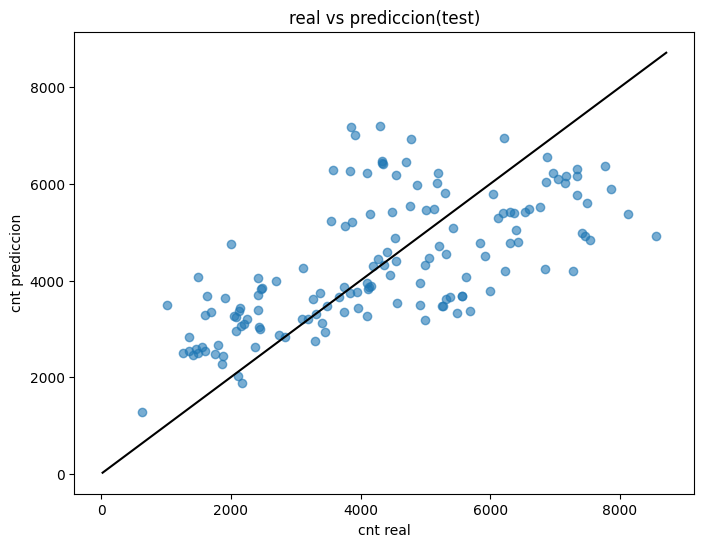

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, pred_test, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="black")

plt.xlabel("cnt real")
plt.ylabel("cnt prediccion")
plt.title("real vs prediccion(test)")
plt.show()

Si bien hay algunos puntos dispersos, se distingue que el modelo sigue la tendencia. Pero en los días que más bicis se alquilan predice por debajo del valor real (subestima), y en los días que menos se alquilan predice por encima (sobreestima).

Modelo 2 (se suma la variable "yr")

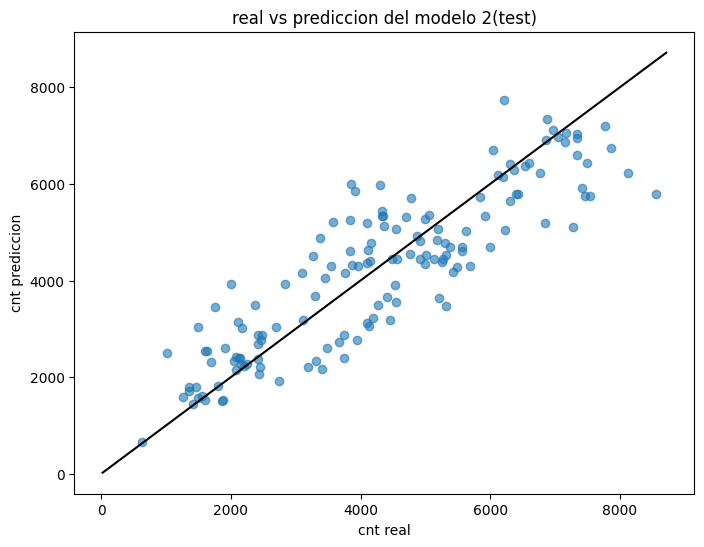

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y2_test, pred_test2, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="black")

plt.xlabel("cnt real")
plt.ylabel("cnt prediccion")
plt.title("real vs prediccion del modelo 2(test)")
plt.show()

Se puede observar en el gráfico del modelo 2 que los puntos se encuentran más agrupados, con una tendencia más marcada y más cercanos a la línea. El modelo 2 sigue subestimando los días de muchos alquileres y sobreestimando los de pocos, pero en mucha menor medida que el primero. Esto indica una mejora muy marcada al agregar la variable del año.

## **Concluciones**


Empezando por el modelo 1, su desempeño obtuvo un R2 de 0.429, el cual es insuficiente para considerar sus predicciones aceptables utilizando 0.50 como parámetro mínimo de rendimiento; su promedio de equivocación es de 1174 bicis. Lo positivo del modelo 1 es que, en contraste con el baseline, fue ampliamente mayor su R2 (0.429 contra -0.019) y con 418 bicis menos de promedio de equivocación (1174 contra 1592). Por otro lado, el modelo 2 logró subir su R2 a 0.763, quedando por debajo del ideal que es 0.80, y bajar el promedio de equivocación a 728 bicis, con la inclusión de una variable más ("yr") a las que ya tenía el modelo 1.

La variable con el coeficiente más grande es "temp" en el modelo 1: a mayor temperatura, más alquileres. En el caso de "hum" y "windspeed", al ser negativos, restan. Como ya están normalizadas entre 0 y 1 podemos comparar entre coeficientes, y coincide con el heatmap, donde "temp" tenía la mayor correlación con "cnt". En la variable "yr" el coeficiente suma 1900 bicis más por día en 2012, en iguales condiciones de clima que en 2011.

De las 3 variables del primer modelo, "temp" es la que más aporta; "hum" y "windspeed" mejoran el modelo en menor medida. Cuando hablamos de clima en general, la temperatura es el dato que más utilizamos para informarnos, pero en este caso el clima solo explica el 43% de la variación de los alquileres, por lo que no alcanza para predecir bien. Por eso sugerimos agregar "yr" a las features que ya tenía el primero. El segundo modelo aprendió que los alquileres eran más altos en 2012 que en 2011, probablemente por el crecimiento del servicio entre un año y el otro. Como limitación, "yr" solo representa los años 2011 y 2012, el modelo puede predecir entre esos años. La variable "atemp" (sensación térmica) fue descartada por colinealidad, y "casual" y "registered", si las sumamos, dan el resultado que queremos predecir ("cnt"), por lo que también fueron descartadas.

El modelo 1 tuvo como resultado 0.473 en R2 de entrenamiento y 0.429 en R2 de test, valores muy similares entre sí. Respecto al modelo 2, su R2 de entrenamiento es 0.717 y, a diferencia del primer modelo, su R2 de test fue mayor, con 0.763. En ambos modelos los valores de test y entrenamiento son similares, lo que indica que no hay sobreajuste: el modelo aprendió la relación general.


Información del dataset:

- yr: año (0 = 2011, 1 = 2012)
- temp: temperatura en °C, normalizada (dividida por 41, el máximo)
- atemp: sensación térmica en °C, normalizada (dividida por 50)
- hum: humedad, normalizada (dividida por 100)
- windspeed: velocidad del viento, normalizada (dividida por 67)
- cnt: cantidad total de bicicletas alquiladas en el día